# 4. Camera Geometry and Epipolar Geometry

Practice for module 4: build `P = K[R | t]`, compute a surface normal, set up two cameras,
compute the Essential and Fundamental matrices, verify the epipolar constraint and draw epipolar lines.
We also recover F from correspondences with the 8-point algorithm.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 80

## 4.1 Projection matrix in homogeneous coordinates

`x = P X` with `P = K [R | t]` (3x4). Changing the principal-point offset only shifts the image.

In [2]:
def K_matrix(f, cx, cy):
    return np.array([[f, 0, cx], [0, f, cy], [0, 0, 1]], dtype=float)

def Ry(deg):
    t = np.deg2rad(deg); c, s = np.cos(t), np.sin(t)
    return np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])

def projection_matrix(K, R, t):
    return K @ np.hstack([R, t.reshape(3, 1)])

def project(P, X):
    Xh = np.vstack([X, np.ones((1, X.shape[1]))])   # to homogeneous
    x = P @ Xh
    return x[:2] / x[2]                              # back to pixels

X = np.array([[0.0, 0.5, -0.5], [0.0, 0.2, 0.3], [5.0, 6.0, 4.0]])
P1 = projection_matrix(K_matrix(500, 320, 240), np.eye(3), np.zeros(3))
P2 = projection_matrix(K_matrix(500, 420, 240), np.eye(3), np.zeros(3))   # only offset changed

print("P =\n", P1)
print("pixels (cx=320):\n", project(P1, X))
print("pixels (cx=420):\n", project(P2, X))
print("difference = pure shift:", project(P2, X) - project(P1, X))

P =
 [[500.   0. 320.   0.]
 [  0. 500. 240.   0.]
 [  0.   0.   1.   0.]]
pixels (cx=320):
 [[320.    361.667 257.5  ]
 [240.    256.667 277.5  ]]
pixels (cx=420):
 [[420.    461.667 357.5  ]
 [240.    256.667 277.5  ]]
difference = pure shift: [[100. 100. 100.]
 [  0.   0.   0.]]


## 4.2 Surface normal via cross product

In [3]:
A, B, C = np.array([0, 0, 0.0]), np.array([1, 0, 0.0]), np.array([0, 1, 1.0])
n = np.cross(B - A, C - A)
n_unit = n / np.linalg.norm(n)
print("normal:", n_unit)
print("perpendicular to both edges:", np.isclose(n @ (B - A), 0), np.isclose(n @ (C - A), 0))

normal: [ 0.    -0.707  0.707]
perpendicular to both edges: True True


## 4.3 Two cameras and a 3D scene

Camera 1 sits at the origin. Camera 2 is moved along the baseline and rotated slightly.
We write camera 2 as `X₂ = R X₁ + t`.

camera 2 center: [ 0.95   0.    -0.371]  baseline length: 1.02


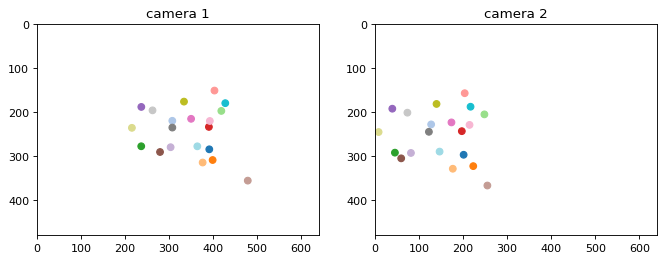

In [4]:
rng = np.random.default_rng(42)
Xw = np.vstack([rng.uniform(-1.5, 1.5, 20), rng.uniform(-1, 1, 20), rng.uniform(4, 8, 20)])

K1 = K_matrix(500, 320, 240)
K2 = K_matrix(550, 310, 250)
R = Ry(-10)
t = np.array([-1.0, 0.0, 0.2])          # baseline: camera 2 is ~1 unit to the right

P_1 = projection_matrix(K1, np.eye(3), np.zeros(3))
P_2 = projection_matrix(K2, R, t)
x1, x2 = project(P_1, Xw), project(P_2, Xw)

C2 = -R.T @ t                           # center of camera 2 in camera-1 coordinates
print("camera 2 center:", C2, " baseline length:", round(np.linalg.norm(C2), 3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, pts, title in zip(axes, [x1, x2], ["camera 1", "camera 2"]):
    ax.scatter(pts[0], pts[1], c=np.arange(20), cmap="tab20")
    ax.set_xlim(0, 640); ax.set_ylim(480, 0); ax.set_aspect("equal"); ax.set_title(title)
plt.show()

## 4.4 Essential and Fundamental matrices

- `E = [t]ₓ R` (normalized coordinates, K known)
- `F = K₂⁻ᵀ E K₁⁻¹` (pixel coordinates)
- Epipolar constraint: `x₂ᵀ F x₁ = 0` for every correspondence.

In [5]:
def skew(v):
    return np.array([[0, -v[2], v[1]], [v[2], 0, -v[0]], [-v[1], v[0], 0]])

def to_h(x):
    return np.vstack([x, np.ones((1, x.shape[1]))])

E = skew(t) @ R
F = np.linalg.inv(K2).T @ E @ np.linalg.inv(K1)

x1h, x2h = to_h(x1), to_h(x2)
residuals = np.einsum("ij,ik,kj->j", x2h, F, x1h)        # x2^T F x1 for each point
n1 = np.linalg.inv(K1) @ x1h; n2 = np.linalg.inv(K2) @ x2h
residuals_E = np.einsum("ij,ik,kj->j", n2, E, n1)

print("rank(E) =", np.linalg.matrix_rank(E), " rank(F) =", np.linalg.matrix_rank(F))
print("max |x2^T F x1| =", np.abs(residuals).max())
print("max |n2^T E n1| =", np.abs(residuals_E).max())

rank(E) = 2  rank(F) = 2
max |x2^T F x1| = 1.249000902703301e-16
max |n2^T E n1| = 1.1102230246251565e-16


## 4.5 Epipoles and epipolar lines

Line in image 2 for point `x₁`: `l₂ = F x₁`. Epipoles are the null vectors of F: `F e₁ = 0`, `Fᵀ e₂ = 0`.
All epipolar lines pass through the epipole, so the correspondence search is 1D.

epipole in image 1: [-961.777  240.   ]
epipole in image 2: [-2440.   250.]


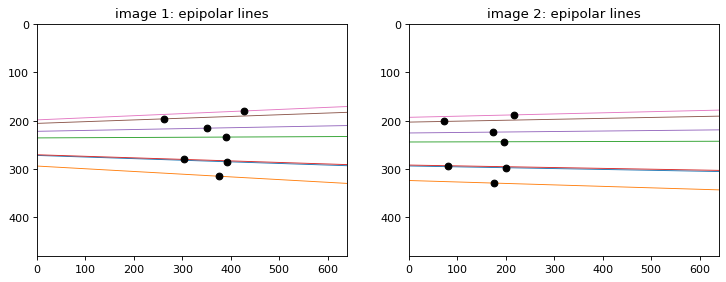

In [6]:
def null_vec(M):
    v = np.linalg.svd(M)[2][-1]
    return v / v[2]

e1, e2 = null_vec(F), null_vec(F.T)
print("epipole in image 1:", e1[:2])
print("epipole in image 2:", e2[:2])

def draw_line(ax, l, xlim=(0, 640)):
    xs = np.array(xlim, dtype=float)
    ax.plot(xs, -(l[0] * xs + l[2]) / l[1], lw=0.8)

idx = range(0, 20, 3)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for i in idx:
    draw_line(axes[1], F @ x1h[:, i])        # lines in image 2 from points in image 1
    draw_line(axes[0], F.T @ x2h[:, i])      # lines in image 1 from points in image 2
for ax, pts, title in zip(axes, [x1, x2], ["image 1", "image 2"]):
    ax.scatter(pts[0, list(idx)], pts[1, list(idx)], c="k", zorder=3)
    ax.set_xlim(0, 640); ax.set_ylim(480, 0); ax.set_aspect("equal"); ax.set_title(title + ": epipolar lines")
plt.show()

## 4.6 Estimating F from correspondences: normalized 8-point algorithm

In practice we don't know R, t, K: we only have matched pixels. Add noise and recover F.

In [7]:
def normalize_pts(x):
    c = x.mean(axis=1, keepdims=True)
    s = np.sqrt(2) / np.mean(np.linalg.norm(x - c, axis=0))
    T = np.array([[s, 0, -s * c[0, 0]], [0, s, -s * c[1, 0]], [0, 0, 1]])
    return T @ to_h(x), T

def eight_point(x1, x2):
    p1, T1 = normalize_pts(x1)
    p2, T2 = normalize_pts(x2)
    A = np.stack([np.kron(p2[:, i], p1[:, i]) for i in range(p1.shape[1])])
    F_est = np.linalg.svd(A)[2][-1].reshape(3, 3)
    U, S, Vt = np.linalg.svd(F_est)
    F_est = U @ np.diag([S[0], S[1], 0]) @ Vt          # enforce rank 2
    F_est = T2.T @ F_est @ T1                           # undo normalization
    return F_est / F_est[2, 2]

rng = np.random.default_rng(0)
F_est = eight_point(x1 + rng.normal(0, 0.5, x1.shape), x2 + rng.normal(0, 0.5, x2.shape))   # 0.5 px noise

def point_line_dist(F, x1, x2):
    l = F @ to_h(x1)
    return np.abs(np.sum(l * to_h(x2), axis=0)) / np.hypot(l[0], l[1])

print("rank(F_est) =", np.linalg.matrix_rank(F_est))
print(f"mean distance to epipolar line, true F:      {point_line_dist(F, x1, x2).mean():.4f} px")
print(f"mean distance to epipolar line, estimated F: {point_line_dist(F_est, x1, x2).mean():.4f} px")

rank(F_est) = 2
mean distance to epipolar line, true F:      0.0000 px
mean distance to epipolar line, estimated F: 0.2397 px


## Summary

- `P = K [R | t]` maps 3D to pixels; the offset only shifts the image.
- Surface normal = cross product of two in-plane vectors.
- `E = [t]ₓ R` (needs K), `F = K₂⁻ᵀ E K₁⁻¹` (pixels); both satisfy `x₂ᵀ F x₁ = 0`.
- Epipolar lines meet at the epipole and reduce matching to a 1D search.
- F can be estimated from ≥ 8 correspondences without knowing the cameras.